# 04 Baselines

Simple forecasts that use only prices known at the run cutoff, scored on the development days. Any model has to beat these. No fitting happens here, so there is nothing to leak between days; each baseline only looks back from D-1 at the cutoff.

## Init

In [1]:
import sys
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _common import load, to_uk, dev_only, UK_TZ

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

def show():
    for ax in plt.gcf().axes:
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

price = dev_only(load("imbalance_price")).set_index("period_start")["price_gbp_per_mwh"]
loc = to_uk(price.index.to_series())
df = pd.DataFrame({"price": price})
df["day"] = loc.dt.tz_localize(None).dt.normalize()
df["hhmm"] = loc.dt.strftime("%H:%M")
df["occ"] = df.groupby(["day", "hhmm"]).cumcount()   # 2nd occurrence of 01:00-02:00 on the autumn clock-change day
print(len(df), "periods,", df["day"].nunique(), "days")

32351 periods, 674 days


## 1. Price as a day x period table

Rows are UK days, columns are clock times (`hhmm`, plus an occurrence counter for the repeated hour on the autumn clock-change day). A baseline is a table of the same shape: the forecast for each day and period. Missing cells (spring-change gap, the one missing half-hour) stay NaN.

In [2]:
wide = df.pivot(index="day", columns=["hhmm", "occ"], values="price")
wide = wide.reindex(pd.date_range(wide.index.min(), wide.index.max(), freq="D"))   # continuous days so shifts mean calendar days
print(wide.shape)

def to_long(F):
    """Look up a day x period forecast table at each row of df."""
    ri = F.index.get_indexer(df["day"])
    ci = F.columns.get_indexer(pd.MultiIndex.from_frame(df[["hhmm", "occ"]]))
    out = np.full(len(df), np.nan)
    ok = (ri >= 0) & (ci >= 0)
    out[ok] = F.to_numpy()[ri[ok], ci[ok]]
    return pd.Series(out, index=df.index)

(674, 50)


## 2. Baselines

Prices for D-2 and earlier are fully known at D-1 07:00/09:00, so `shift(2)` on the table is safe. The 'recent level' baselines also use prices from D-1 up to the cutoff; a period is treated as usable once its start is at least 1 hour before the cutoff (an assumed settlement-publication delay; the data do not record when prices appeared).

| Baseline | Forecast for period p of day D |
| --- | --- |
| `global_median` | median of all earlier-known prices (expanding, up to D-2) |
| `d2_same` | price at p on D-2 |
| `med7_same` | median of p over D-8..D-2 |
| `med28_same` | median of p over D-29..D-2 |
| `level24h_07` / `_09` | median of the 24 h of prices before the cutoff, same for every p |
| `med28_plus_level_09` | `med28_same` shifted by (24 h level at 09:00 minus the median of `med28` over those same clock times) |

In [3]:
known = wide.shift(2)
B = {}
B["d2_same"] = to_long(known)
B["med7_same"] = to_long(known.rolling(7, min_periods=4).median())
B["med28_same"] = to_long(known.rolling(28, min_periods=14).median())

# expanding global median up to D-2
vals = wide.to_numpy()
glob = pd.Series(index=wide.index, dtype=float)
for i in range(2, len(wide)):
    v = vals[: i - 1].ravel()           # days up to D-2
    glob.iloc[i] = np.nanmedian(v) if np.isfinite(v).any() else np.nan
B["global_median"] = df["day"].map(glob)

# recent level from prices known at the cutoff
def cutoff_utc(day, hour):
    d1 = pd.Timestamp(day) - pd.Timedelta(days=1)
    return (d1 + pd.Timedelta(hours=hour)).tz_localize(UK_TZ, ambiguous=False, nonexistent="shift_forward").tz_convert("UTC")

def level24(hour):
    t = price.index
    lv = {}
    for d in wide.index:
        c = cutoff_utc(d, hour)
        w = price[(t >= c - pd.Timedelta(hours=25)) & (t <= c - pd.Timedelta(hours=1))]
        lv[d] = w.median() if len(w) >= 24 else np.nan
    return pd.Series(lv)

L = {h: level24(h) for h in (7, 9)}
B["level24h_07"] = df["day"].map(L[7])
B["level24h_09"] = df["day"].map(L[9])

# med28 shifted to the recent level: compare the 24 h level with what med28 says those clock times usually cost
m28 = known.rolling(28, min_periods=14).median()
shift_ = {}
for d in wide.index:
    c = cutoff_utc(d, 9)
    t = price.index
    w = price[(t >= c - pd.Timedelta(hours=25)) & (t <= c - pd.Timedelta(hours=1))]
    if len(w) < 24 or d - pd.Timedelta(days=1) not in m28.index:
        shift_[d] = np.nan
        continue
    wl = to_uk(w.index.to_series())
    prev = m28.loc[d]                          # med28 row for day D uses data up to D-2 (safe)
    keys = pd.MultiIndex.from_arrays([wl.dt.strftime("%H:%M"), wl.groupby([wl.dt.date, wl.dt.strftime("%H:%M")]).cumcount() * 0])
    ref = pd.Series(prev.reindex(keys).to_numpy()).median()
    shift_[d] = w.median() - ref
B["med28_plus_level_09"] = B["med28_same"] + df["day"].map(pd.Series(shift_))

P = pd.DataFrame(B)
print(P.notna().mean().round(3).to_string())

d2_same                0.997
med7_same              0.992
med28_same             0.978
global_median          0.997
level24h_07            0.997
level24h_09            0.997
med28_plus_level_09    0.978


## 3. Scoring

Score on days where every baseline has a forecast, starting after the warm-up of the longest look-back. Metrics: MAE, RMSE and bias (forecast minus actual), all in £/MWh.

In [4]:
score_days = P.dropna().index
y = df["price"]
common = P.dropna().index
print(len(common), "periods,", df.loc[common, "day"].nunique(), "days from", df.loc[common, "day"].min().date(), "to", df.loc[common, "day"].max().date())

def metrics(f, idx):
    e = f.loc[idx] - y.loc[idx]
    return pd.Series({"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "bias": e.mean()})

res = pd.DataFrame({k: metrics(P[k], common) for k in P}).T.round(1).sort_values("MAE")
print(res.to_string())

31622 periods, 659 days from 2024-10-16 to 2026-08-05
                      MAE  RMSE  bias
med28_same           31.4  63.5   1.7
med7_same            33.3  64.9   1.2
global_median        34.1  65.9   1.0
med28_plus_level_09  34.8  66.1   3.1
level24h_09          36.0  67.5  -1.2
level24h_07          36.2  67.7  -1.5
d2_same              41.8  87.2   0.1


### By quarter

A baseline that wins overall might lose in one regime. MAE by quarter of the target day.

In [5]:
q = df.loc[common, "day"].dt.to_period("Q").astype(str)
t = pd.DataFrame({k: (P.loc[common, k] - y.loc[common]).abs().groupby(q).mean() for k in P}).round(1)
t["n_periods"] = q.value_counts().sort_index()
print(t.to_string())
print()
tb = pd.DataFrame({k: (P.loc[common, k] - y.loc[common]).groupby(q).mean() for k in P}).round(1)
print("bias by quarter:")
print(tb.to_string())

        d2_same  med7_same  med28_same  global_median  level24h_07  level24h_09  med28_plus_level_09  n_periods
day                                                                                                            
2024Q4     42.7       34.3        31.5           33.5         37.6         37.4                 35.5       3696
2025Q1     49.8       38.1        36.6           38.4         39.2         39.5                 38.7       4318
2025Q2     45.0       36.6        34.6           37.5         41.3         41.0                 39.9       4366
2025Q3     38.4       32.4        29.7           32.7         34.3         34.0                 33.8       4416
2025Q4     32.7       26.7        25.4           27.2         28.8         28.6                 27.8       4416
2026Q1     35.9       29.5        28.7           29.6         32.3         32.2                 30.9       4314
2026Q2     47.0       35.0        32.6           36.0         38.9         39.0                 37.2    

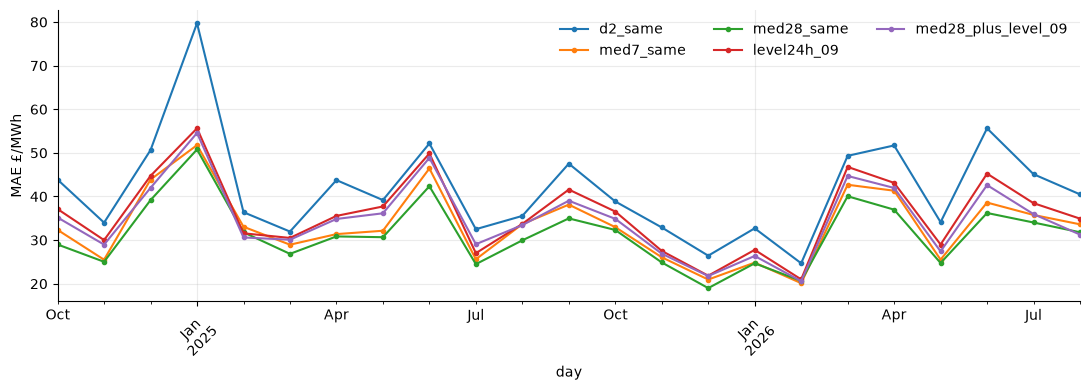

In [6]:
m = df.loc[common, "day"].dt.to_period("M").dt.to_timestamp()
mm = pd.DataFrame({k: (P.loc[common, k] - y.loc[common]).abs().groupby(m).mean() for k in ["d2_same", "med7_same", "med28_same", "level24h_09", "med28_plus_level_09"]})
mm.plot(marker="o", ms=3)
plt.ylabel("MAE \u00a3/MWh"); plt.legend(frameon=False, ncol=3)
show()

### Where the error comes from

MAE and RMSE diverge because of the tail. Compare MAE on all periods with MAE after dropping the largest 1% of actual prices, and the share of squared error from them.

In [7]:
thr = y.loc[common].quantile(.99)
tail = y.loc[common] > thr
rows = {}
for k in P:
    e = (P.loc[common, k] - y.loc[common])
    rows[k] = {"MAE all": e.abs().mean(), "MAE excl top 1%": e[~tail].abs().mean(), "share of SSE from top 1%": (e[tail] ** 2).sum() / (e ** 2).sum()}
print(f"top 1% = actual price above \u00a3{thr:.0f}")
print(pd.DataFrame(rows).T.round(2).to_string())

top 1% = actual price above £179
                     MAE all  MAE excl top 1%  share of SSE from top 1%
d2_same                41.76            40.04                      0.36
med7_same              33.32            31.54                      0.58
med28_same             31.42            29.58                      0.62
global_median          34.06            32.01                      0.60
level24h_07            36.18            34.26                      0.55
level24h_09            36.03            34.13                      0.55
med28_plus_level_09    34.83            33.11                      0.56


## 4. Does the forecast pick the right periods within a day?

A battery operator cares about which half-hours are cheap or expensive, not only the level. For each day, take the 8 periods (4 hours) the forecast ranks lowest and highest and count how many are also among the actual 8 lowest/highest. Random choice would hit 8/48 = 0.17. Baselines that are constant within a day (levels) have no ranking and are left out.

In [8]:
def hit_rate(f, k=8, largest=True):
    d = pd.DataFrame({"day": df.loc[common, "day"], "f": f.loc[common], "y": y.loc[common]})
    out = []
    for _, g in d.groupby("day"):
        if len(g) < 40 or g["f"].nunique() < 5:
            continue
        pick = g["f"].nlargest(k).index if largest else g["f"].nsmallest(k).index
        act = g["y"].nlargest(k).index if largest else g["y"].nsmallest(k).index
        out.append(len(set(pick) & set(act)) / k)
    return np.mean(out), len(out)

rk = {}
for k in ["d2_same", "med7_same", "med28_same", "med28_plus_level_09"]:
    hi, n = hit_rate(P[k], largest=True)
    lo, _ = hit_rate(P[k], largest=False)
    rk[k] = {"top-8 hit rate": hi, "bottom-8 hit rate": lo, "days": n}
print(pd.DataFrame(rk).T.round(3).to_string())

                     top-8 hit rate  bottom-8 hit rate   days
d2_same                       0.329              0.242  659.0
med7_same                     0.407              0.277  659.0
med28_same                    0.453              0.326  659.0
med28_plus_level_09           0.453              0.326  659.0


## Findings (development days, 659 days from 2024-10-16 to 2026-08-05)

- **Best baseline: the 28-day same-period median** (`med28_same`): MAE £31.4, RMSE 63.5, bias +1.7. It is also the best in every quarter. The 7-day median (33.3), global median (34.1) and 24 h level (36.0-36.2) follow. "Same period two days ago" is the worst on MAE (41.8) and on RMSE (87.2), because it copies the previous day's spikes.
- **Longer look-back wins.** Prices carry little day-to-day signal (notebook 02: lag-1 correlation 0.16), so averaging more days beats reacting to recent ones. A model's gain has to come from the weather/demand features, not from recency.
- **Level adjustment did not help.** Shifting the 28-day profile by the recent 24 h level (`med28_plus_level_09`, MAE 34.8) is worse than the profile alone. The 24 h level alone is also worse than the profile, so the clock-time shape matters more than the recent level. This implementation is crude, so a better-designed recent-level feature inside a model is not ruled out.
- **Level drift shows in bias.** The global median is biased by -20 in 2026Q3 and +19 in 2025Q2; the 28-day profile stays within about ±7 in every quarter.
- **Spikes dominate squared error.** The top 1% of actual prices (above £179) account for 58-62% of squared error for the profile baselines, and removing them lowers MAE by about £2. RMSE is therefore very sensitive to a handful of periods; report MAE and RMSE together and consider a tail-aware measure.
- **Ranking within a day.** The 28-day profile picks 45% of the day's 8 highest-price periods and 33% of the 8 lowest correctly (random 17%); D-2 same period gets 33% and 24%. So the intraday shape has real skill for timing even though level accuracy is modest. The level-adjusted baseline has the same hit rate because it adds a constant within the day.
- **Targets to beat.** MAE about £31 and RMSE about 63.5 (development days, unconditional on cutoff since the price-based baselines barely differ between 07:00 and 09:00).
- **Caveat.** The "usable prices" rule (period start at least 1 h before the cutoff) is an assumed publication delay; the data do not record when prices appeared.